In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv(r"C:\Users\sarth\Downloads\Telegram Desktop\1776250375-P2-Healthcare Analytics for Doctor Visits.csv"
   
)


if "Unnamed: 0" in df.columns:
    df.drop(columns=["Unnamed: 0"], inplace=True)

print("Dataset Shape:", df.shape)
print("\nColumn Names:\n", df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("\nCleaned Dataset:")
print(df.head())

df.to_csv("cleaned_healthcare_data.csv", index=False)

print("\nCleaned dataset saved successfully.")

Dataset Shape: (5190, 12)

Column Names:
 ['visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   visits     5190 non-null   int64  
 1   gender     5190 non-null   str    
 2   age        5190 non-null   float64
 3   income     5190 non-null   float64
 4   illness    5190 non-null   int64  
 5   reduced    5190 non-null   int64  
 6   health     5190 non-null   int64  
 7   private    5190 non-null   str    
 8   freepoor   5190 non-null   str    
 9   freerepat  5190 non-null   str    
 10  nchronic   5190 non-null   str    
 11  lchronic   5190 non-null   str    
dtypes: float64(2), int64(4), str(6)
memory usage: 486.7 KB

Missing Values:
visits       0
gender       0
age          0
income       0
illness      

In [ ]:
print("Descriptive Statistical Analysis:")
print(df.describe())

print("\nAverage Doctor Visits:", df["visits"].mean())

print("Median Doctor Visits:", df["visits"].median())

print("Maximum Doctor Visits:", df["visits"].max())

print("Minimum Doctor Visits:", df["visits"].min())

print("Average Age:", df["age"].mean())

print("Average Income:", df["income"].mean())

print("Average Illness:", df["illness"].mean())

print("Average Health Score:", df["health"].mean())

Descriptive Statistical Analysis:
            visits          age       income      illness      reduced  \
count  3870.000000  3870.000000  3870.000000  3870.000000  3870.000000   
mean      0.389147     0.410762     0.582550     1.670543     1.151680   
std       0.899433     0.200034     0.377685     1.421045     3.286601   
min       0.000000     0.190000     0.000000     0.000000     0.000000   
25%       0.000000     0.220000     0.250000     1.000000     0.000000   
50%       0.000000     0.320000     0.550000     1.000000     0.000000   
75%       1.000000     0.620000     0.900000     2.750000     0.000000   
max       9.000000     0.720000     1.500000     5.000000    14.000000   

            health  
count  3870.000000  
mean      1.577778  
std       2.330537  
min       0.000000  
25%       0.000000  
50%       1.000000  
75%       2.000000  
max      12.000000  

Average Doctor Visits: 0.3891472868217054
Median Doctor Visits: 0.0
Maximum Doctor Visits: 9
Minimum Doctor V

gender
female    0.449710
male      0.319645
Name: visits, dtype: float64
gender
female    2068
male      1802
Name: count, dtype: int64


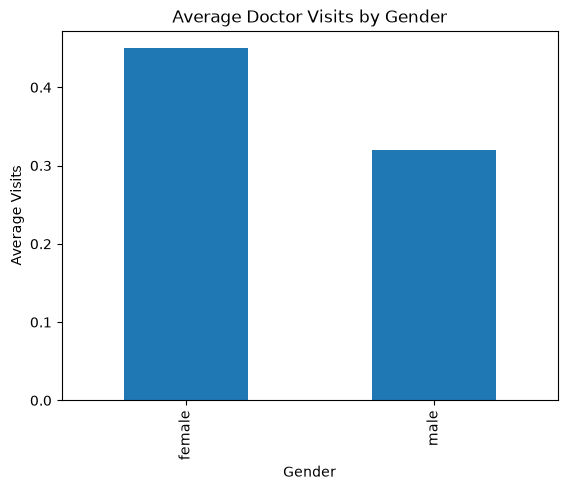

In [7]:
print(df.groupby("gender")["visits"].mean())
print(df["gender"].value_counts())

df.groupby("gender")["visits"].mean().plot(kind="bar")
plt.title("Average Doctor Visits by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Visits")
plt.show()

age_group
0-0.2      0.285455
0.2-0.4    0.307298
0.4-0.6    0.405028
0.6-0.8    0.555662
0.8-1.0         NaN
Name: visits, dtype: float64


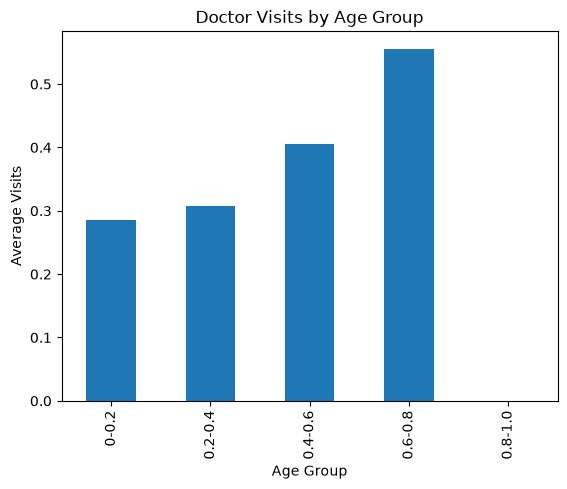

In [8]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[-1, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["0-0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-1.0"],
    include_lowest=True
)

print(df.groupby("age_group", observed=False)["visits"].mean())

df.groupby("age_group", observed=False)["visits"].mean().plot(kind="bar")
plt.title("Doctor Visits by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Visits")
plt.show()

income_group
Low             0.503339
Lower-Middle    0.388190
Upper-Middle    0.316135
High            0.287958
Name: visits, dtype: float64


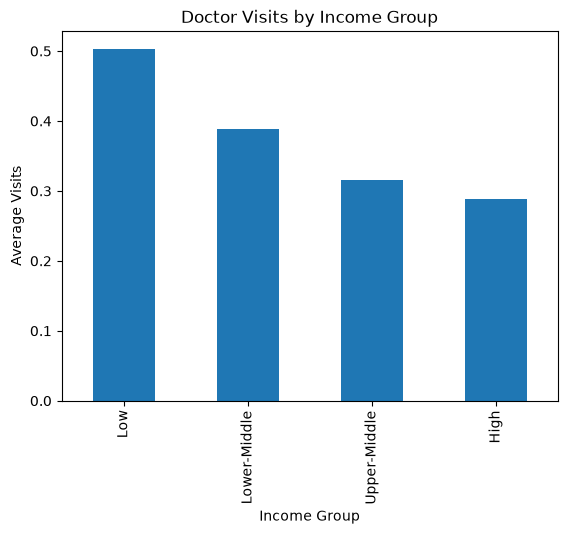

In [9]:
df["income_group"] = pd.qcut(
    df["income"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"],
    duplicates="drop"
)

print(df.groupby("income_group", observed=False)["visits"].mean())

df.groupby("income_group", observed=False)["visits"].mean().plot(kind="bar")
plt.title("Doctor Visits by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Average Visits")
plt.show()

         count      mean  median
illness                         
0          870  0.127586     0.0
1         1211  0.382329     0.0
2          821  0.447016     0.0
3          485  0.445361     0.0
4          258  0.608527     0.0
5          225  0.853333     0.0


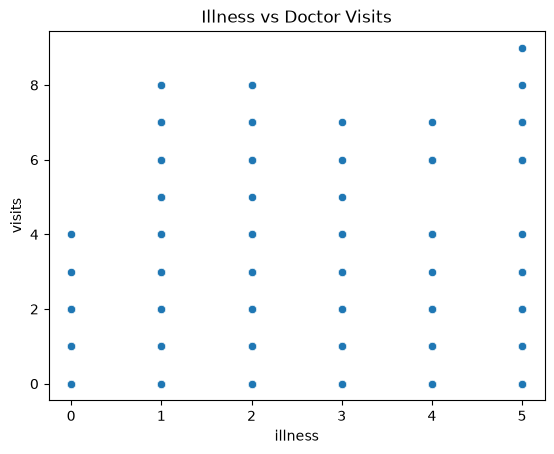

Correlation: 0.18546878811812592


In [10]:
print(df.groupby("illness")["visits"].agg(["count", "mean", "median"]))

sns.scatterplot(data=df, x="illness", y="visits")
plt.title("Illness vs Doctor Visits")
plt.show()

print("Correlation:", df["illness"].corr(df["visits"]))

health
0     0.300378
1     0.372740
2     0.398568
3     0.424242
4     0.540541
5     0.530303
6     0.637255
7     0.918033
8     0.487805
9     0.656250
10    1.523810
11    0.833333
12    1.000000
Name: visits, dtype: float64


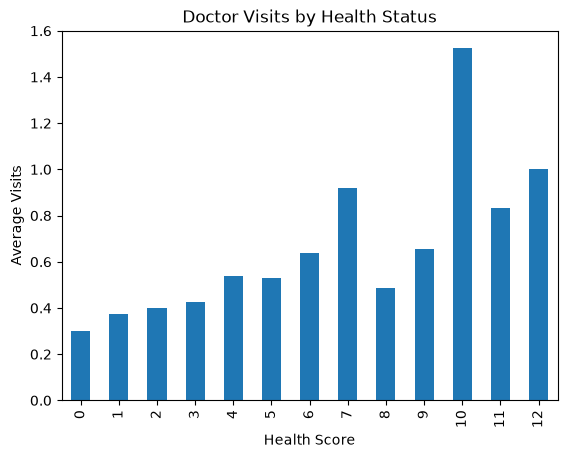

In [11]:
print(df.groupby("health")["visits"].mean())

df.groupby("health")["visits"].mean().plot(kind="bar")
plt.title("Doctor Visits by Health Status")
plt.xlabel("Health Score")
plt.ylabel("Average Visits")
plt.show()


 private
         count      mean  median
private                         
no        2088  0.403257     0.0
yes       1782  0.372615     0.0


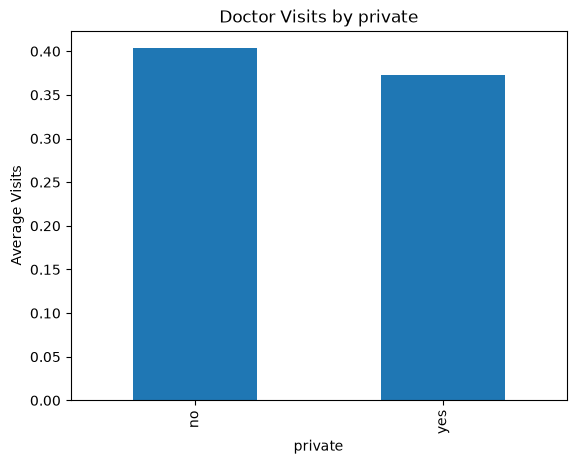


 freepoor
          count      mean  median
freepoor                         
no         3676  0.400163     0.0
yes         194  0.180412     0.0


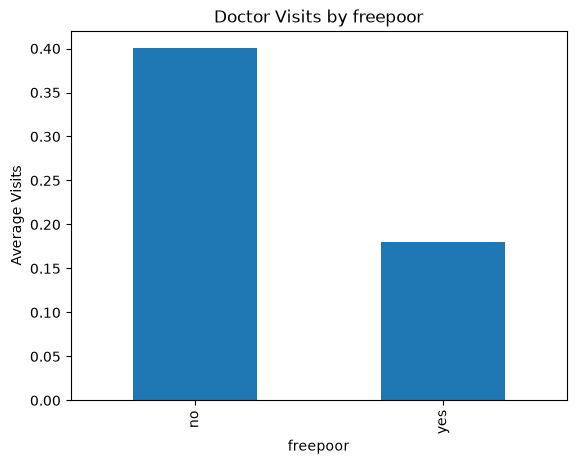


 freerepat
           count      mean  median
freerepat                         
no          3102  0.334300     0.0
yes          768  0.610677     0.0


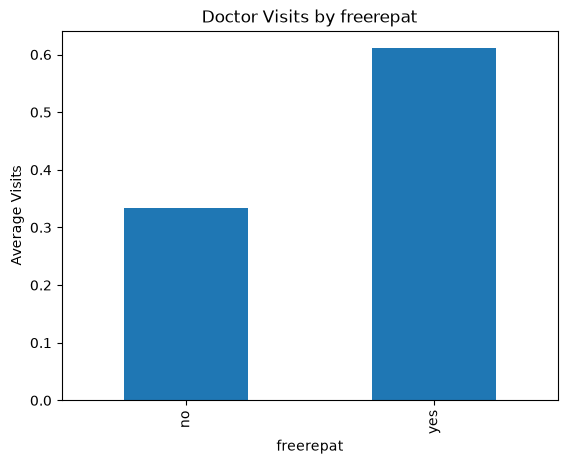

In [12]:
for col in ["private", "freepoor", "freerepat"]:
    print("\n", col)
    print(df.groupby(col)["visits"].agg(["count", "mean", "median"]))

    df.groupby(col)["visits"].mean().plot(kind="bar")
    plt.title("Doctor Visits by " + col)
    plt.xlabel(col)
    plt.ylabel("Average Visits")
    plt.show()


 nchronic
          count      mean  median
nchronic                         
no         2192  0.376825     0.0
yes        1678  0.405244     0.0


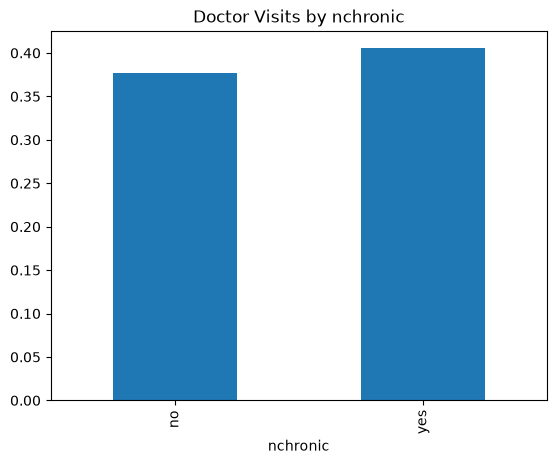


 lchronic
          count      mean  median
lchronic                         
no         3294  0.346691     0.0
yes         576  0.631944     0.0


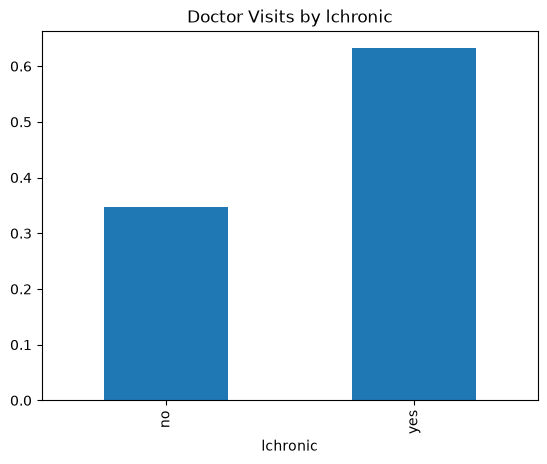

In [13]:
for col in ["nchronic", "lchronic"]:
    print("\n", col)
    print(df.groupby(col)["visits"].agg(["count", "mean", "median"]))

    df.groupby(col)["visits"].mean().plot(kind="bar")
    plt.title("Doctor Visits by " + col)
    plt.show()

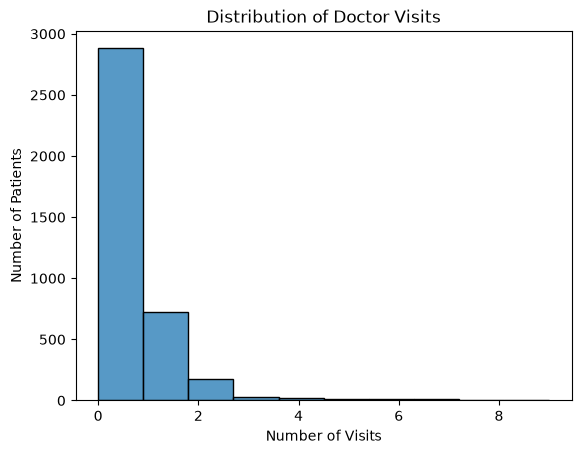

In [14]:
sns.histplot(data=df, x="visits", bins=10)
plt.title("Distribution of Doctor Visits")
plt.xlabel("Number of Visits")
plt.ylabel("Number of Patients")
plt.show()

           visits       age    income   illness   reduced    health
visits   1.000000  0.123836 -0.076916  0.185469  0.403213  0.149304
age      0.123836  1.000000 -0.203979  0.167224  0.105057  0.003812
income  -0.076916 -0.203979  1.000000 -0.134864 -0.053131 -0.096036
illness  0.185469  0.167224 -0.134864  1.000000  0.191833  0.309573
reduced  0.403213  0.105057 -0.053131  0.191833  1.000000  0.246496
health   0.149304  0.003812 -0.096036  0.309573  0.246496  1.000000


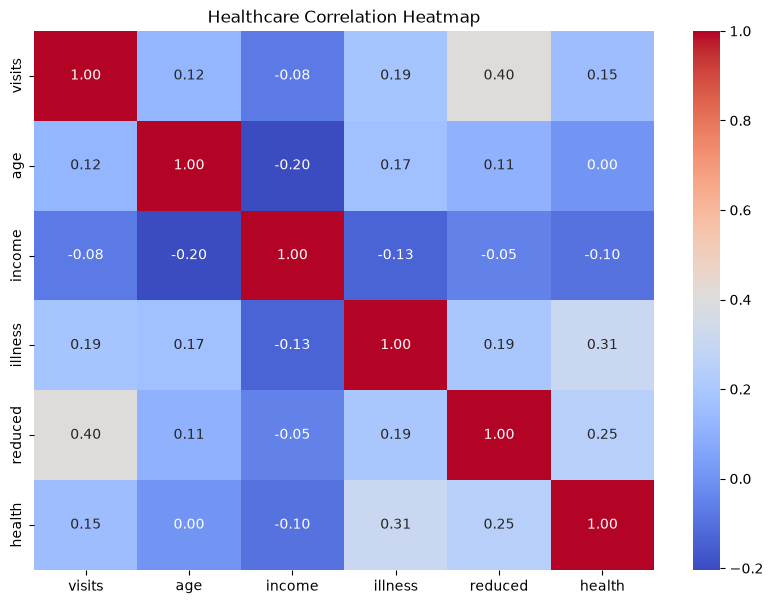

In [15]:
correlation_matrix = df.select_dtypes(include="number").corr()

print(correlation_matrix)

plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Healthcare Correlation Heatmap")
plt.show()

In [16]:
threshold = 2

frequent_visitors = df[df["visits"] > threshold]

print(frequent_visitors)
print("Frequent Visitors:", len(frequent_visitors))
print("Percentage:", round(len(frequent_visitors) / len(df) * 100, 2), "%")

      visits  gender   age  income  illness  reduced  health private freepoor  \
35         3    male  0.19    0.00        1        4       0      no       no   
41         4    male  0.19    0.55        4        5       2      no       no   
46         3  female  0.19    0.15        1        4       2      no       no   
47         8  female  0.19    0.25        2        7       0      no       no   
55         4  female  0.19    0.15        3        1       0      no       no   
...      ...     ...   ...     ...      ...      ...     ...     ...      ...   
920        4  female  0.72    0.25        3        0       0      no       no   
943        4  female  0.72    0.35        4        0       0     yes       no   
970        6  female  0.72    0.35        4       13       4     yes       no   
983        6  female  0.72    0.25        1        5       2      no       no   
1022       4    male  0.72    0.25        0        0       4      no       no   

     freerepat nchronic lch

health        0         1         2         3         4         5         6   \
gender                                                                         
female  0.359423  0.426136  0.506024  0.414815  0.636364  0.540541  0.630769   
male    0.235227  0.321526  0.241176  0.434109  0.430233  0.517241  0.648649   

health        7         8         9         10        11        12  
gender                                                              
female  0.769231  0.619048  0.818182  1.294118  0.733333  1.222222  
male    1.181818  0.350000  0.300000  2.500000  1.000000  0.800000  


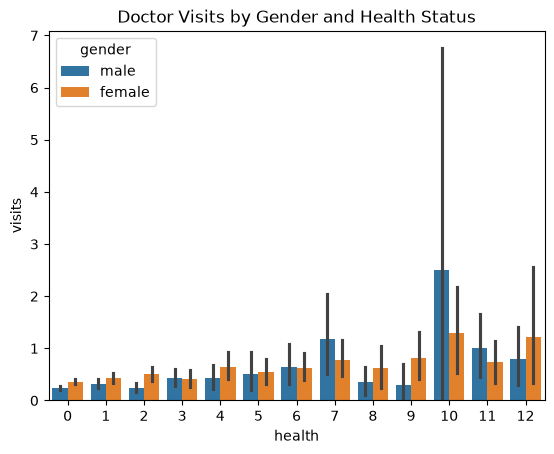

In [17]:
print(pd.pivot_table(
    df,
    values="visits",
    index="gender",
    columns="health",
    aggfunc="mean"
))

sns.barplot(data=df, x="health", y="visits", hue="gender")
plt.title("Doctor Visits by Gender and Health Status")
plt.show()

In [18]:
print("Total Records:", len(df))
print("Average Doctor Visits:", df["visits"].mean())
print("Median Doctor Visits:", df["visits"].median())
print("Maximum Doctor Visits:", df["visits"].max())
print("Average Age:", df["age"].mean())
print("Average Income:", df["income"].mean())
print("Average Illness Frequency:", df["illness"].mean())
print("Average Health Score:", df["health"].mean())

print("\nAverage Visits by Gender:")
print(df.groupby("gender")["visits"].mean())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nAnalytics Completed Successfully!")

Total Records: 3870
Average Doctor Visits: 0.3891472868217054
Median Doctor Visits: 0.0
Maximum Doctor Visits: 9
Average Age: 0.4107622739018088
Average Income: 0.5825503875968993
Average Illness Frequency: 1.6705426356589148
Average Health Score: 1.5777777777777777

Average Visits by Gender:
gender
female    0.449710
male      0.319645
Name: visits, dtype: float64

Missing Values:
visits          0
gender          0
age             0
income          0
illness         0
reduced         0
health          0
private         0
freepoor        0
freerepat       0
nchronic        0
lchronic        0
age_group       0
income_group    0
dtype: int64

Analytics Completed Successfully!
